In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [2]:
print("Taxis Dataset:")
display(df.head())

Taxis Dataset:


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (6433, 14)
Number of Rows: 6433
Number of Columns: 14


In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [5]:
missing_columns = df.isnull().sum()

missing_columns = missing_columns[missing_columns > 0]

print("Columns with Missing Values:")
print(missing_columns)

Columns with Missing Values:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [7]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

print("Missing Payment Values:", df['payment'].isnull().sum())

Missing Payment Values: 0


In [8]:
location_columns = [
    'pickup_zone',
    'dropoff_zone',
    'pickup_borough',
    'dropoff_borough'
]

df = df.dropna(subset=location_columns)

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (6383, 14)


In [9]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Final Dataset Shape: (6383, 14)


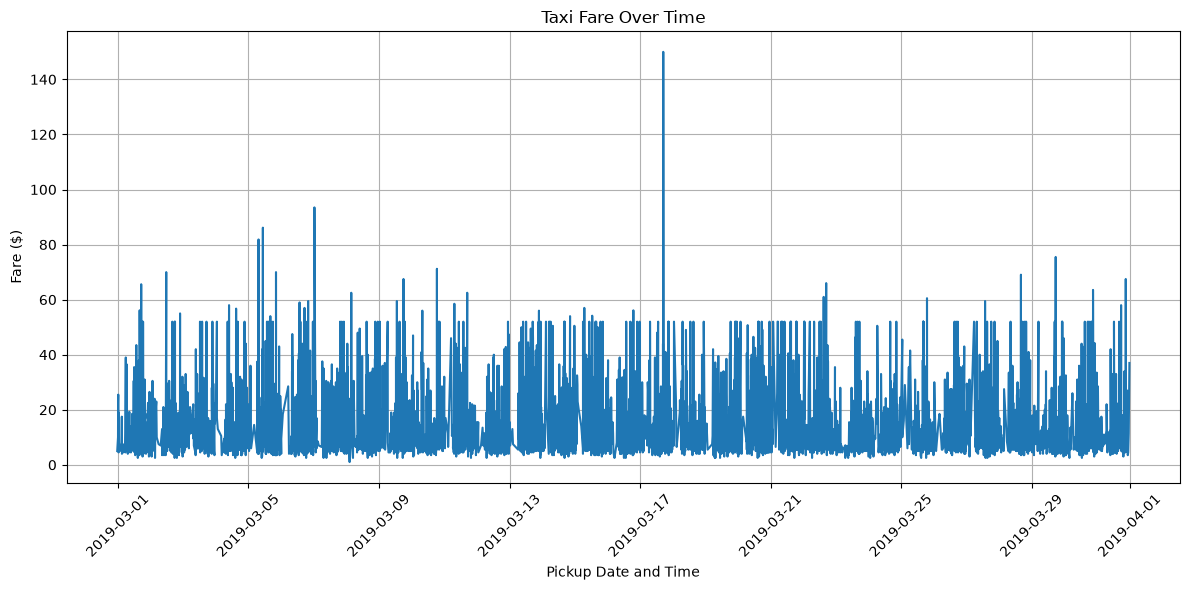

In [10]:
df['pickup'] = pd.to_datetime(df['pickup'])

df_sorted = df.sort_values('pickup')

plt.figure(figsize=(12, 6))

plt.plot(df_sorted['pickup'], df_sorted['fare'])

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Date and Time')
plt.ylabel('Fare ($)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

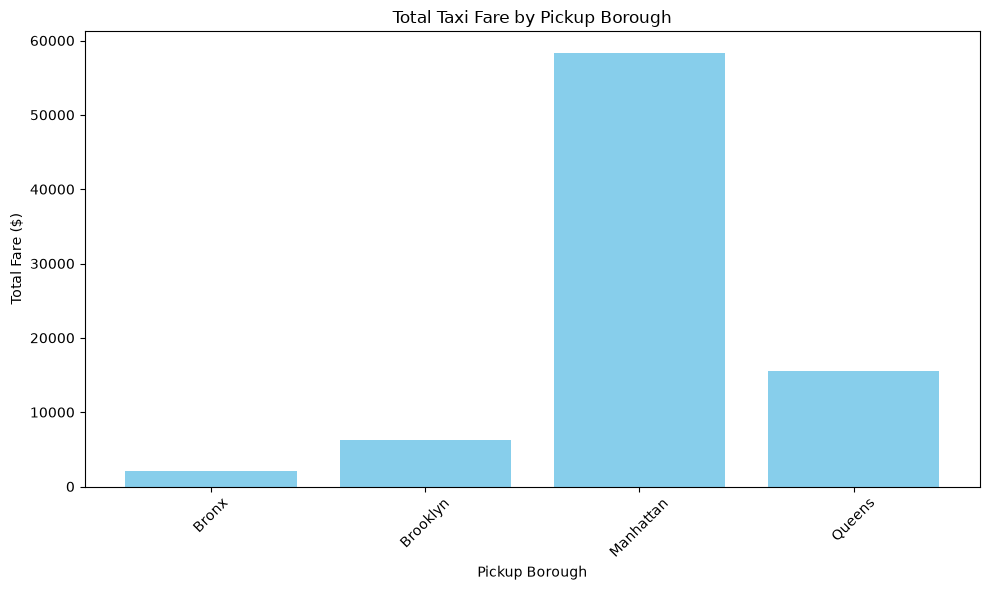

In [11]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(10, 6))

plt.bar(borough_fare.index, borough_fare.values, color='skyblue')

plt.title('Total Taxi Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

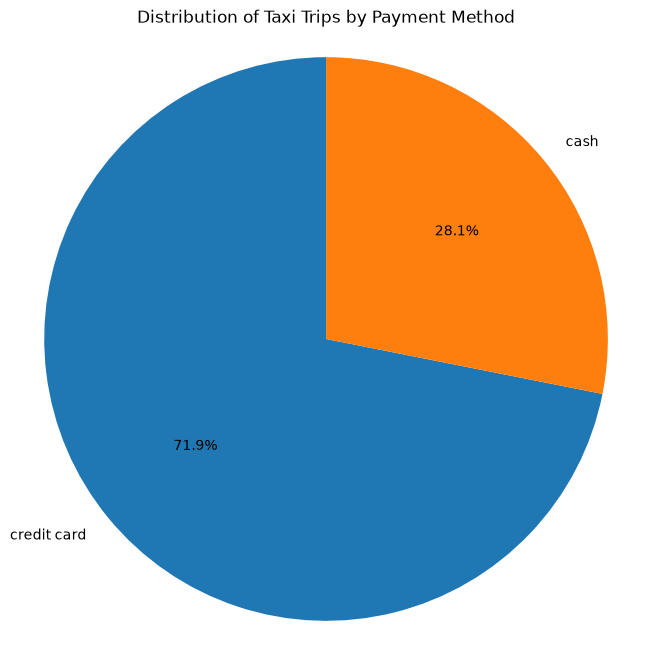

In [12]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Taxi Trips by Payment Method')

plt.axis('equal')
plt.show()

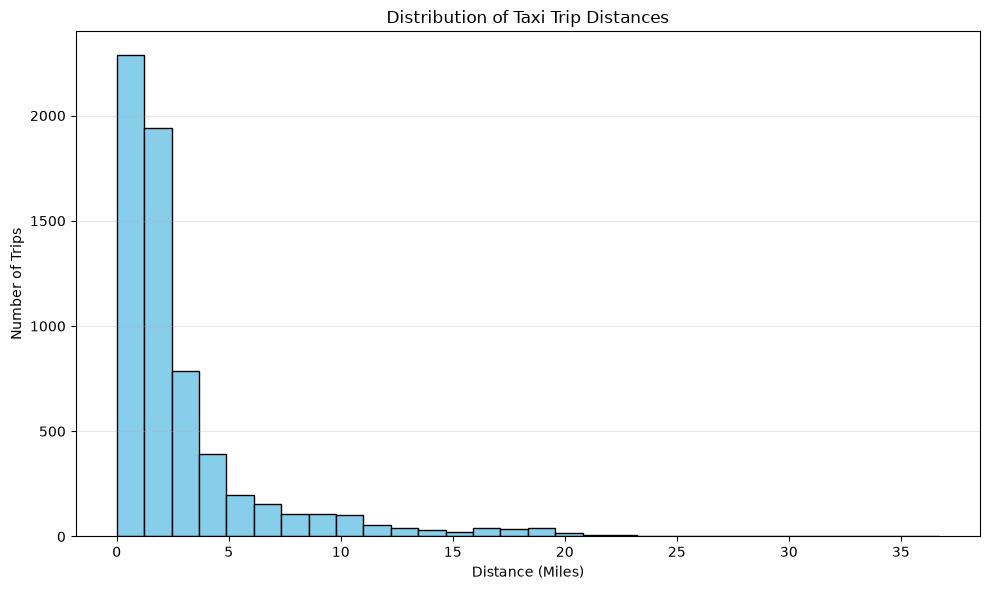

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(df['distance'], bins=30, color='skyblue', edgecolor='black')

plt.title('Distribution of Taxi Trip Distances')
plt.xlabel('Distance (Miles)')
plt.ylabel('Number of Trips')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

<Figure size 1000x600 with 0 Axes>

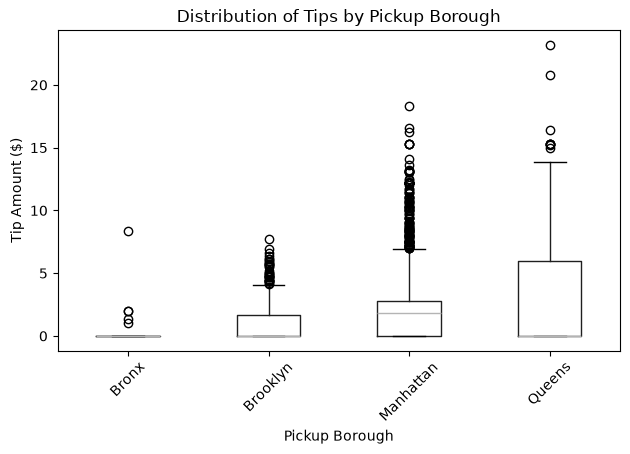

In [14]:
plt.figure(figsize=(10, 6))

df.boxplot(
    column='tip',
    by='pickup_borough',
    grid=False
)

plt.title('Distribution of Tips by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

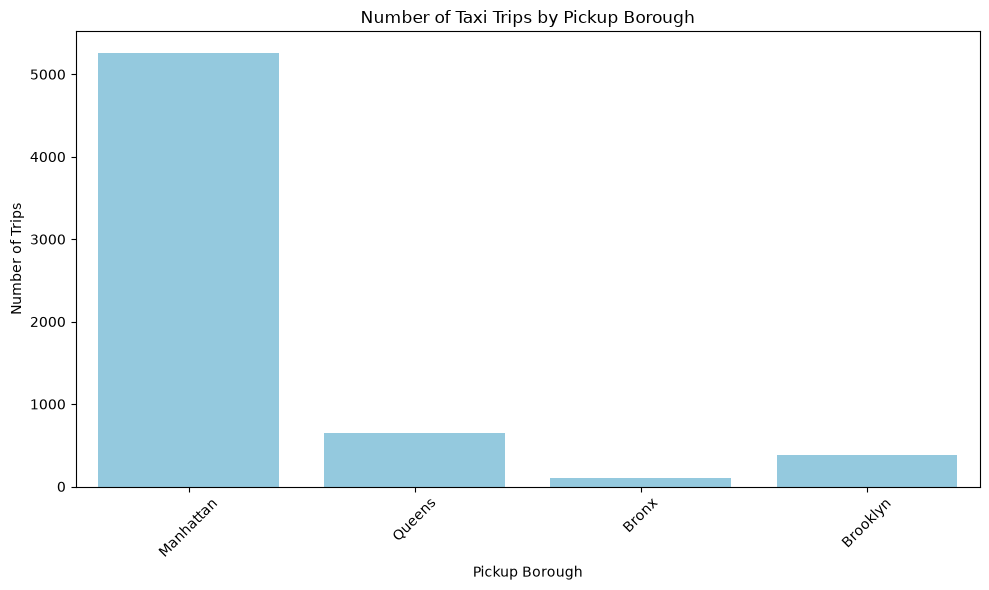

In [15]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='pickup_borough',
    color='skyblue'
)

plt.title('Number of Taxi Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

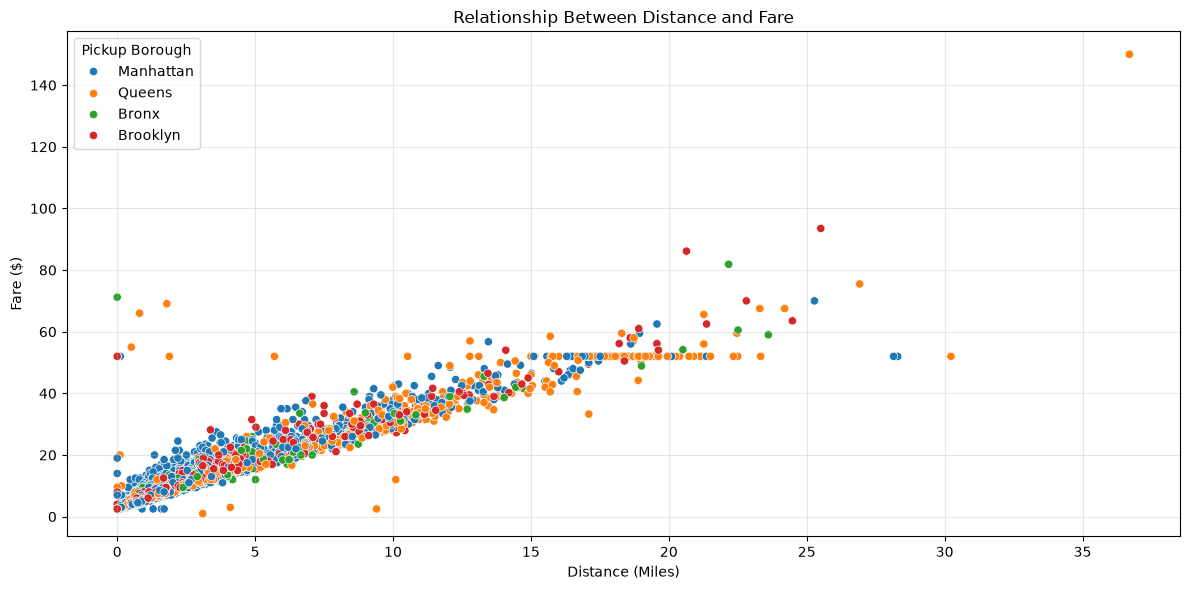

In [16]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance (Miles)')
plt.ylabel('Fare ($)')

plt.legend(title='Pickup Borough')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [17]:
### Observation

### The scatter plot shows a positive relationship between taxi trip
### distance and fare. Longer trips generally have higher fares.

### Some outliers are present, representing trips with unusually
### high fares or distances.

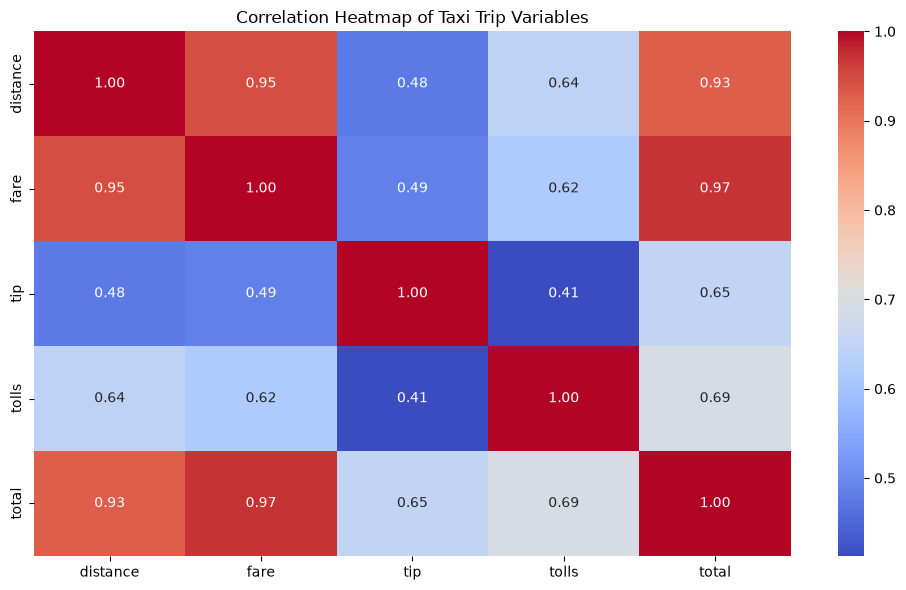

In [18]:
numerical_columns = ['distance', 'fare', 'tip', 'tolls', 'total']

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Taxi Trip Variables')
plt.tight_layout()

plt.show()

In [19]:
### Observation

### The correlation heatmap shows the relationships between
### distance, fare, tip, tolls, and total.

### A positive correlation between distance and fare indicates
### that longer taxi trips generally have higher fares.

### Fare and total are expected to show a strong positive
### correlation because fare contributes to the total amount.

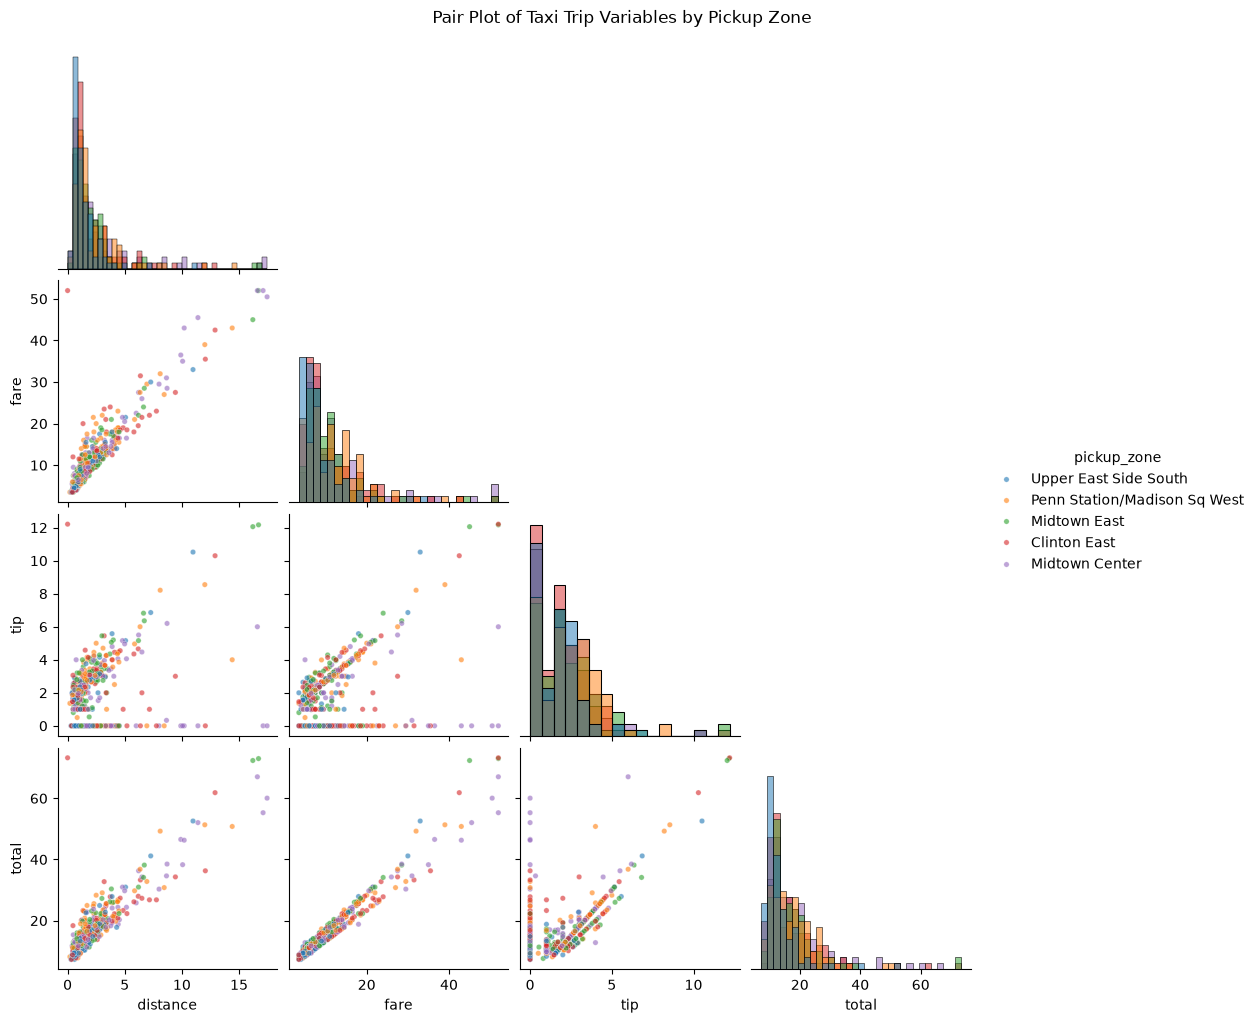

In [20]:

top_zones = df['pickup_zone'].value_counts().head(5).index


pair_data = df[df['pickup_zone'].isin(top_zones)]

pair_data = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

g = sns.pairplot(
    data=pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.6, 's': 15}
)

g.fig.suptitle('Pair Plot of Taxi Trip Variables by Pickup Zone', y=1.02)

plt.show()

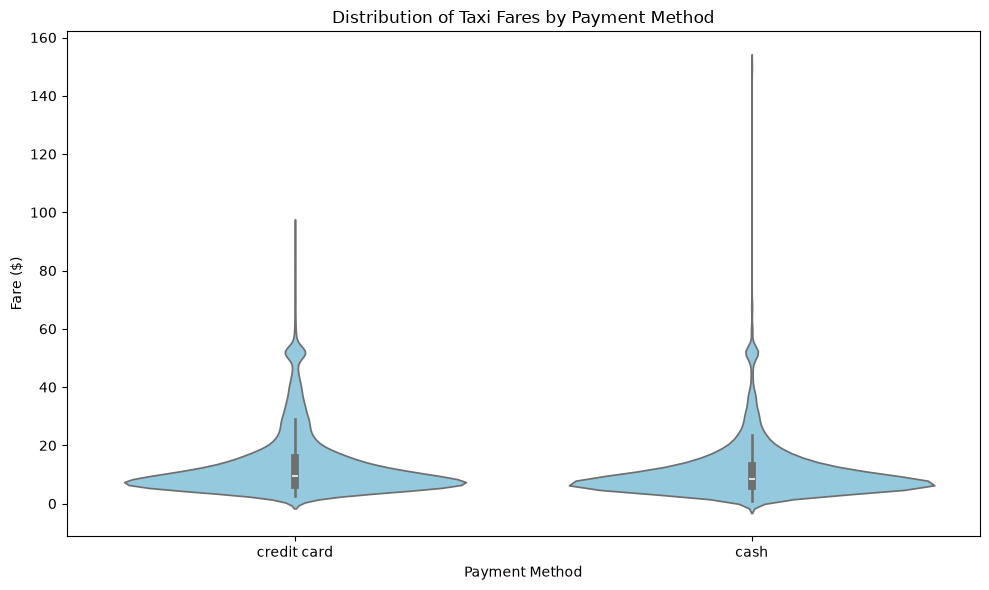

In [22]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    color='skyblue'
)

plt.title('Distribution of Taxi Fares by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')

plt.tight_layout()
plt.show()


In [ ]:
### Observation

### The violin plot compares taxi fare distributions
### across different payment methods.

### The width of each violin represents the density
### of taxi fares within a particular range.

### This visualization helps identify differences
### in fare distributions between payment methods.